# 5 — Neural Network Models for Volatility Prediction (Unified Supplement)

**Question.** Does the wording of a company's Item 7 (Management's Discussion and Analysis) predict its share-price volatility over the next 12 months beyond what last year's volatility already tells us—and how do **architecture** (additive residual vs. gated interaction vs. chunk attention), **text representation** (Bag-of-Words TF-IDF vs. FinBERT), **loss function** (MSE vs. Huber), and **data/resource scaling** affect performance?

### What This Unified Notebook Covers
This single, self-contained notebook combines and harmonizes all neural-network experiments, fixes, ablations, and scaling benchmarks so it runs cleanly top-to-bottom from a fresh kernel with zero cross-notebook file dependencies:

1. **Reproducible Temporal Protocol (Section 5.2–5.4):** Exact alignment with `02-Linear-models.ipynb` (`splits.csv`, `alex-02-ridge-results.csv`), strict per-split leakage-free TF-IDF and FinBERT standardization (`X_tune` vs. `X_full`), and an expanded Ridge penalty grid (`ALPHAS` up to `1000`).
2. **Three Parameter-Efficient Neural Architectures (Section 5.5):**
   - **`ResidualTextNet`:** Single-hidden-layer additive residual MLP initialized at `"copy last year"` with isolated `AdamW` weight decay (exempting the skip connection and all biases) and full-window refitting.
   - **`GatedInteractionMLP`:** Concatenates hidden text features with prior volatility $z_{\text{before}}$ and modulates the text residual via a learned sigmoid gate $g(\mathbf{x}, z_{\text{before}}) \in (0, 1)$, allowing text reliance to adapt to a firm's volatility regime.
   - **`FinBERTAttentionNet` (optional when chunk embeddings are present):** Masked additive attention-pooling over frozen 512-token FinBERT chunks + gated residual head, paired with a uniform mean-pooling ablation.
3. **Validation-Only Sweeps (Section 5.6):** Tunes `(HIDDEN, DROPOUT, WEIGHT_DECAY)` and Huber loss $\delta$ strictly on `MAIN_WINDOW` validation years, then applies the winning hyperparameters consistently across all architectures for a strictly controlled comparison.
4. **Unified 12-Split Evaluation & Diagnostics (Section 5.7–5.8):** Fast CPU execution (pre-materialized dense tensors once per split, no duplicate `no refit` training) producing one unified results table, `level` vs. `spread` decomposition, takeover sensitivity (`logvol_after < -5.0`), 3-seed word attribution, and learned gate interpretability plots.
5. **1,000× Scaling & Parallelism Benchmark (Section 5.9):** Learning curve, data-volume slope, sparse-per-batch vs. pre-dense speedup, CPU strong scaling (`1–8` threads), and stateless Map-only `HashingVectorizer` vs. Map-Reduce `CountVectorizer + TF-IDF`.

## 5.1 — Setup, Imports & Configuration

In [1]:
import gc
import gzip
import json
import os
import pickle
import sys
import tarfile
import time
import urllib.request
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.feature_extraction.text import CountVectorizer, HashingVectorizer, TfidfTransformer
from sklearn.linear_model import Ridge
import torch
from torch import nn

ROOT = Path("..")                              # notebook lives one level below repo root
PROCESSED = ROOT / "data" / "processed"
OUTPUT = ROOT / "data" / "output"
BOW_DIR = PROCESSED / "bow"
BOW_DIR.mkdir(parents=True, exist_ok=True)
kogan_dir = ROOT / "data" / "raw" / "kogan"
edgar_dir = PROCESSED / "edgar_matched"
KOGAN_URL = "https://www.cs.cmu.edu/~ark/10K/data/"

sys.path.insert(0, str(ROOT / "Alex"))         # shared scoring.py from 02-Linear-models
import scoring

# --- split & display config ----------------------------------------------------------------------
MAIN_WINDOW = "paper"

# --- optional FinBERT overrides (leave None for automatic detection) -----------------------------
FINBERT_DOC_PATH = None                        # e.g. PROCESSED / "finbert_item7.npy"
FINBERT_DOC_KEY = None                         # e.g. key inside data.pkl
CHUNK_EMB_PATH = PROCESSED / "finbert_item7_chunks.npz"
EXTRACT_CHUNKS_IF_MISSING = False              # set True on GPU/Colab to extract 512-token FinBERT chunks
MAX_CHUNKS = 16
FINBERT_MODEL_NAME = "ProsusAI/finbert"

# --- text & ridge features -----------------------------------------------------------------------
N_WORDS = 5000
MIN_DF = 50
TOKEN = r"(?u)\b[a-z]{2,}\b"
ALPHAS = [0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]

# --- default network hyperparameters (updated by validation sweep in Section 5.6) ----------------
HIDDEN = 16
ATTN_DIM = 64
DROPOUT = 0.5
LR = 1e-3
WEIGHT_DECAY = 5e-2
BATCH = 256
MAX_EPOCHS = 40
PATIENCE = 5
HUBER_DELTA = 1.0
SEEDS = [0, 1, 2]
VERY_LOW = -5.0                                # takeover-type reports, as in 04-Volatility-Checking

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device} | PyTorch CPU threads: {torch.get_num_threads()} / {os.cpu_count()} logical cores")

Using device: cpu | PyTorch CPU threads: 8 / 16 logical cores


## 5.2 — Reports, Split Verification & FinBERT Loaders

Loads `data.pkl` via `scoring.frame`, checks exact split alignment with `splits.csv` and `alex-02-ridge-results.csv`, and safely auto-detects document-level (and optional chunk-level) FinBERT embeddings.

In [2]:
with open(PROCESSED / "data.pkl", "rb") as f:
    d = pickle.load(f)
df = scoring.frame(d)
y = df["logvol_after"].to_numpy()
prev = df["logvol_before"].to_numpy()
year_arr = df["year"].to_numpy()
keys = df["key"].tolist()
print(f"{len(df):,} reports, {df.year.min()}-{df.year.max()}")

def as_mask(m):
    m = np.asarray(m)
    if m.dtype == bool:
        return m
    out = np.zeros(len(df), dtype=bool)
    out[m] = True
    return out

# --- Item 7 text source metadata -----------------------------------------------------------------
meta = pd.read_csv(PROCESSED / "dataset.csv", parse_dates=["date"]).drop(columns="item7_source", errors="ignore")
assert meta["key"].is_unique, "key must identify one report"
src_file = PROCESSED / "item7_source.csv"
USE_EDGAR = src_file.exists() and edgar_dir.exists() and any(edgar_dir.glob("*.jsonl.gz"))
TEXT_TAG = "edgar" if USE_EDGAR else "kogan"
if USE_EDGAR:
    meta = meta.merge(pd.read_csv(src_file)[["key", "item7_source"]], on="key", how="inner")
    assert not meta.duplicated(["cik", "year"]).any(), "company + year must identify one report"
else:
    meta["item7_source"] = "kogan"

data = df[["key"]].merge(meta, on="key", how="left", validate="one_to_one")
missing = data["item7_source"].isna()
assert not missing.any(), f"{int(missing.sum())} reports in data.pkl have no Item 7 source"
assert (data["year"].to_numpy() == year_arr).all(), "filing years differ between data.pkl and dataset.csv"
assert np.allclose(data["logvol_after"], y) and np.allclose(data["logvol_before"], prev), "labels differ"
print("Item 7 source:", data["item7_source"].value_counts().to_dict(),
      "(EDGAR rule from 03)" if USE_EDGAR else "(Kogan only: item7_source.csv / edgar_matched not found)")

# --- Safe automatic Item 7 FinBERT embedding loader (handles ragged entries in data.pkl) ---------
def load_finbert_doc(d_obj, n_rows, processed_dir, explicit_path=None, explicit_key=None):
    def _extract_2d(arr):
        try:
            arr = np.asarray(arr)
        except (ValueError, TypeError):
            return None
        if arr.ndim == 2 and arr.shape[0] == n_rows and arr.shape[1] >= 64 and np.issubdtype(arr.dtype, np.number):
            return arr.astype(np.float32)
        return None

    if explicit_path is not None:
        p = Path(explicit_path)
        if p.exists() and p.suffix == ".npy":
            emb = _extract_2d(np.load(p))
            if emb is not None:
                return emb, f"file:{p.name}"
        elif p.exists() and p.suffix == ".npz":
            z = np.load(p)
            for k in z.files:
                emb = _extract_2d(z[k])
                if emb is not None:
                    return emb, f"file:{p.name}[{k}]"

    if explicit_key is not None and isinstance(d_obj, dict) and explicit_key in d_obj:
        emb = _extract_2d(d_obj[explicit_key])
        if emb is not None:
            return emb, f"data.pkl[{explicit_key!r}]"

    if isinstance(d_obj, dict):
        cands = []
        for k, v in d_obj.items():
            emb = _extract_2d(v)
            if emb is not None:
                kl = str(k).lower()
                score = (4 if "7" in kl else 0) + (3 if "finbert" in kl else 0) + (2 if "emb" in kl else 0) + (1 if emb.shape[1] == 768 else 0)
                cands.append((score, k, emb))
        if cands:
            cands.sort(key=lambda t: -t[0])
            return cands[0][2], f"data.pkl[{cands[0][1]!r}]"

    for pat in ["*finbert*7*.npy", "*item7*.npy", "*finbert*.npy", "*emb*.npy"]:
        for p in sorted(processed_dir.glob(pat)):
            emb = _extract_2d(np.load(p))
            if emb is not None:
                return emb, f"file:{p.name}"
    return None, None

X_FINBERT_DOC, FINBERT_DOC_SRC = load_finbert_doc(d, len(df), PROCESSED, FINBERT_DOC_PATH, FINBERT_DOC_KEY)
if X_FINBERT_DOC is not None:
    print(f"Loaded document-level FinBERT embeddings: shape={X_FINBERT_DOC.shape} from {FINBERT_DOC_SRC}")
else:
    avail = list(d.keys()) if isinstance(d, dict) else type(d).__name__
    print(f"Document-level FinBERT not auto-detected (data.pkl keys: {avail}). Set FINBERT_DOC_KEY/PATH to enable.")

27,142 reports, 1996-2006
Item 7 source: {'kogan': 27142} (Kogan only: item7_source.csv / edgar_matched not found)
Loaded document-level FinBERT embeddings: shape=(27142, 1536) from data.pkl['X']


In [3]:
# Split table and alignment verification with splits.csv and alex-02-ridge-results.csv
rows = []
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        train, test = (as_mask(m) for m in scoring.masks(df, T, window))
        ty = sorted(set(year_arr[train]))
        rows.append({"window": window, "test_year": T, "train_years": f"{ty[0]}-{ty[-1]}",
                     "validate_year": ty[-1], "train_reports": int(train.sum()), "test_reports": int(test.sum())})
split_table = pd.DataFrame(rows)

shared = pd.read_csv(OUTPUT / "splits.csv")
for r in shared.itertuples():
    train, _ = scoring.masks(df, r.test_year, r.window)
    assert as_mask(train).sum() == r.train_reports
assert set(shared.window) == set(scoring.WINDOWS)
print("Windows match data/output/splits.csv.")

copy_vs_line = scoring.evaluate(df, scoring.predict_copy, name="copy last year")
alex_file = OUTPUT / "alex-02-ridge-results.csv"
if alex_file.exists():
    alex = pd.read_csv(alex_file)
    keys_ = ["window", "test_year"]
    theirs = alex[alex.model == "copy last year"].set_index(keys_)[["test_reports", "mse", "baseline_mse"]].sort_index()
    ours = copy_vs_line.set_index(keys_)[["test_reports", "mse", "baseline_mse"]].sort_index()
    pd.testing.assert_frame_equal(ours, theirs, check_dtype=False)
    print("Exact match on test reports, copy-last-year MSE, and straight-line MSE with 02.")
else:
    alex = None
    print(f"{alex_file.name} not found: only splits.csv verifies alignment with 02.")

display(split_table)

Windows match data/output/splits.csv.
Exact match on test reports, copy-last-year MSE, and straight-line MSE with 02.


,window,test_year,train_years,validate_year,train_reports,test_reports
0,paper,2001,1996-2000,2000,9747,2299
1,paper,2002,1997-2001,2001,10788,2587
2,paper,2003,1998-2002,2002,11399,3217
3,paper,2004,1999-2003,2003,12474,3168
4,paper,2005,2000-2004,2004,13422,3121
5,paper,2006,2001-2005,2005,14392,3003
6,strict,2001,1996-1999,1999,7596,2299
7,strict,2002,1997-2000,2000,8489,2587
8,strict,2003,1998-2001,2001,8812,3217
9,strict,2004,1999-2002,2002,9257,3168


In [4]:
def annual(logvol):
    return np.exp(logvol) * np.sqrt(252)

by_year = df.groupby("year").agg(
    reports=("key", "size"),
    typical_vol_before=("logvol_before", lambda v: annual(v.mean())),
    typical_vol_after=("logvol_after", lambda v: annual(v.mean())),
    corr_before_after=("logvol_before", lambda v: np.corrcoef(v, df.loc[v.index, "logvol_after"])[0, 1]),
)
by_year.style.format({"typical_vol_before": "{:.0%}", "typical_vol_after": "{:.0%}", "corr_before_after": "{:.2f}"})

,reports,typical_vol_before,typical_vol_after,corr_before_after
year,,,,
1996,1258,52%,51%,0.87
1997,1976,53%,55%,0.83
1998,2142,54%,69%,0.77
1999,2220,67%,72%,0.80
2000,2151,69%,75%,0.80
2001,2299,76%,65%,0.82
2002,2587,64%,62%,0.81
2003,3217,57%,46%,0.83
2004,3168,44%,39%,0.83


## 5.3 — Text to Word Counts & Optional FinBERT Chunk Loader

Candidate word counts (`min_df = 50`, English stop words removed) are computed once and cached to `data/processed/bow/`. If pre-extracted 512-token FinBERT chunk embeddings exist at `data/processed/finbert_item7_chunks.npz` (or `EXTRACT_CHUNKS_IF_MISSING = True` on a GPU), they are also loaded here for `FinBERTAttentionNet`.

In [5]:
def kogan_file(year):
    f = kogan_dir / f"{year}.tok.tgz"
    if not f.exists():
        kogan_dir.mkdir(parents=True, exist_ok=True)
        print("downloading", f.name)
        urllib.request.urlretrieve(KOGAN_URL + f.name, f)
    return f

def load_year_texts(year):
    rows = data[data["year"] == year]
    want_edgar = {(int(r.cik), int(r.year)): r.key for r in rows.itertuples() if r.item7_source == "edgar"}
    want_kogan = {r.key for r in rows.itertuples() if r.item7_source == "kogan"}
    texts = {}
    if want_edgar:
        with gzip.open(edgar_dir / f"{year}.jsonl.gz", "rt") as f:
            for line in f:
                rec = json.loads(line)
                key = want_edgar.get((int(rec["cik"]), int(rec["year"])))
                if key is not None:
                    texts[key] = rec["section_7"]
    if want_kogan:
        with tarfile.open(kogan_file(year)) as tar:
            for m in tar:
                if m.isfile():
                    key = Path(m.name).name.split(".")[0]
                    if key in want_kogan:
                        texts[key] = tar.extractfile(m).read().decode("utf-8", "replace")
    missing = set(rows["key"]) - set(texts)
    assert not missing, f"{year}: no text found for {len(missing)} reports, e.g. {sorted(missing)[:2]}"
    return [texts[k] for k in rows["key"]]

years_sorted = sorted(int(v) for v in np.unique(year_arr))
order = np.concatenate([np.flatnonzero(year_arr == yr) for yr in years_sorted])

cache_npz, cache_json = BOW_DIR / f"candidates_{TEXT_TAG}.npz", BOW_DIR / f"candidates_{TEXT_TAG}.json"
cached = None
if cache_npz.exists() and cache_json.exists():
    cached = json.loads(cache_json.read_text())
    if cached["keys"] != keys:
        cached = None
        print("saved word counts are for a different set of reports: counting again")
if cached is not None:
    X_counts = sp.load_npz(cache_npz).tocsr()
    vocab, timings = cached["vocab"], cached["timings"]
    print("loaded saved word counts")
else:
    def all_texts():
        for yr in years_sorted:
            yield from load_year_texts(yr)
    t0 = time.perf_counter()
    vec = CountVectorizer(min_df=MIN_DF, stop_words="english", token_pattern=TOKEN, dtype=np.int32)
    X_sorted = vec.fit_transform(all_texts()).tocsr()
    X_counts = X_sorted[np.argsort(order)]
    timings = {"count_seconds": time.perf_counter() - t0, "n_reports": int(X_counts.shape[0])}
    vocab = [str(w) for w in vec.get_feature_names_out()]
    sp.save_npz(cache_npz, X_counts)
    cache_json.write_text(json.dumps({"keys": keys, "vocab": vocab, "timings": timings}))

assert X_counts.shape == (len(df), len(vocab)), "row order must match `df`"
vocab = np.array(vocab)
print("count matrix (reports x candidate words):", X_counts.shape, "| timings:", {k: round(v, 1) for k, v in timings.items()})

# --- Optional FinBERT chunk embeddings loader / GPU extractor ------------------------------------
def extract_and_save_finbert_chunks(out_path, max_chunks=MAX_CHUNKS):
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(FINBERT_MODEL_NAME)
    enc = AutoModel.from_pretrained(FINBERT_MODEL_NAME).to(device)
    enc.eval()

    emb_arr = np.zeros((len(df), max_chunks, 768), dtype=np.float16)
    mask_arr = np.zeros((len(df), max_chunks), dtype=bool)
    for yr in years_sorted:
        yr_idx = np.flatnonzero(year_arr == yr)
        yr_texts = load_year_texts(yr)
        t0 = time.perf_counter()
        for row_idx, txt in zip(yr_idx, yr_texts):
            ids = tok(txt, add_special_tokens=False, truncation=False)["input_ids"]
            chunks_ids = [ids[i:i + 510] for i in range(0, max(1, len(ids)), 510)][:max_chunks]
            n_c = len(chunks_ids)
            seqs = [[tok.cls_token_id] + c + [tok.sep_token_id] for c in chunks_ids]
            max_len = max(len(s) for s in seqs)
            input_ids = torch.full((n_c, max_len), tok.pad_token_id, dtype=torch.long, device=device)
            attn_mask = torch.zeros((n_c, max_len), dtype=torch.long, device=device)
            for k, s in enumerate(seqs):
                input_ids[k, :len(s)] = torch.tensor(s, dtype=torch.long, device=device)
                attn_mask[k, :len(s)] = 1
            with torch.no_grad():
                out = enc(input_ids=input_ids, attention_mask=attn_mask).last_hidden_state
                m = attn_mask.unsqueeze(-1).float()
                pooled = (out * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
            emb_arr[row_idx, :n_c] = pooled.cpu().numpy().astype(np.float16)
            mask_arr[row_idx, :n_c] = True
        print(f"Extracted {yr}: {len(yr_idx):,} reports in {time.perf_counter() - t0:.1f}s")
    np.savez_compressed(out_path, embeddings=emb_arr, mask=mask_arr, keys=np.array(keys))
    return emb_arr, mask_arr

X_CHUNKS, CHUNK_MASK = None, None
if CHUNK_EMB_PATH.exists():
    z = np.load(CHUNK_EMB_PATH, allow_pickle=True)
    X_CHUNKS, CHUNK_MASK = z["embeddings"], z["mask"].astype(bool)
    if "keys" in z.files:
        assert list(z["keys"]) == keys, "Chunk keys do not match data.pkl!"
    print(f"Loaded FinBERT chunks: {X_CHUNKS.shape}, avg valid chunks/report={CHUNK_MASK.sum(axis=1).mean():.2f}")
elif EXTRACT_CHUNKS_IF_MISSING:
    X_CHUNKS, CHUNK_MASK = extract_and_save_finbert_chunks(CHUNK_EMB_PATH)
else:
    print(f"Chunk embeddings not found at {CHUNK_EMB_PATH} (skipping chunk-attention; set EXTRACT_CHUNKS_IF_MISSING=True on GPU to build).")

loaded saved word counts
count matrix (reports x candidate words): (27142, 15344) | timings: {'count_seconds': 91.2, 'n_reports': 27142}
Chunk embeddings not found at ..\data\processed\finbert_item7_chunks.npz (skipping chunk-attention; set EXTRACT_CHUNKS_IF_MISSING=True on GPU to build).


## 5.4 — Leakage-Free Features, Split Structure & Expanded Ridge Baseline

All vocabulary selection, sublinear TF-IDF weighting, FinBERT z-scoring, and target standardization are fitted strictly on `fit_idx` during tuning/early stopping (`X_tune`) and refitted on `tr_idx` for final test evaluation (`X_full`).

In [6]:
def mse(a, b):
    return float(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

def split_key(train, test):
    return (tuple(sorted(int(v) for v in set(year_arr[as_mask(train)]))), int(year_arr[as_mask(test)][0]))

def build_features(fit_mask, transform_mask):
    fit_idx = np.flatnonzero(fit_mask)
    counts_fit = X_counts[fit_idx]
    in_reports = np.asarray((counts_fit > 0).sum(axis=0)).ravel()
    total = np.asarray(counts_fit.sum(axis=0)).ravel()
    eligible = np.flatnonzero(in_reports >= MIN_DF)
    cols = np.sort(eligible[np.argsort(-total[eligible], kind="stable")[:N_WORDS]])

    rows = np.flatnonzero(fit_mask | transform_mask)
    tfidf = TfidfTransformer(sublinear_tf=True).fit(counts_fit[:, cols])
    X = tfidf.transform(X_counts[rows][:, cols]).astype(np.float32).tocsr()
    pos = np.full(len(df), -1, dtype=np.int64)
    pos[rows] = np.arange(len(rows))
    return X, pos, cols, tfidf

def demean_by_year(values, idx):
    out = np.zeros(len(df), dtype=np.float32)
    for yr in np.unique(year_arr[idx]):
        m = idx[year_arr[idx] == yr]
        out[m] = (values[m] - values[m].mean()).astype(np.float32)
    return out

def standardize_dense(X_all, fit_idx, eval_rows):
    mu = X_all[fit_idx].mean(axis=0, keepdims=True)
    sd = X_all[fit_idx].std(axis=0, keepdims=True) + 1e-6
    X_sub = ((X_all[eval_rows] - mu) / sd).astype(np.float32)
    pos = np.full(len(df), -1, dtype=np.int64)
    pos[eval_rows] = np.arange(len(eval_rows))
    return X_sub, pos

def chunk_norm_stats(chunks_all, mask_all, fit_idx):
    valid = chunks_all[fit_idx][mask_all[fit_idx]].astype(np.float32)
    mu = valid.mean(axis=0, keepdims=True)
    sd = valid.std(axis=0, keepdims=True) + 1e-6
    return torch.from_numpy(mu).to(device), torch.from_numpy(sd).to(device)

def make_split(train, test):
    train, test = as_mask(train), as_mask(test)
    assert len(set(year_arr[test])) == 1, "one test year at a time"
    years = sorted(int(v) for v in set(year_arr[train]))
    val_year = years[-1]

    fit_mask = train & (year_arr != val_year)
    val_mask = train & (year_arr == val_year)
    tr_idx, te_idx = np.flatnonzero(train), np.flatnonzero(test)
    fit_idx, val_idx = np.flatnonzero(fit_mask), np.flatnonzero(val_mask)

    X_tune, pos_tune, cols_tune, tfidf_tune = build_features(fit_mask, val_mask)
    X_full, pos_full, cols_full, tfidf_full = build_features(train, test)
    X_te_nr = tfidf_tune.transform(X_counts[te_idx][:, cols_tune]).astype(np.float32)
    pos_te_nr = np.full(len(df), -1, dtype=np.int64)
    pos_te_nr[te_idx] = np.arange(len(te_idx))

    mu_fit, sd_fit = float(y[fit_idx].mean()), float(y[fit_idx].std())
    mu_full, sd_full = float(y[tr_idx].mean()), float(y[tr_idx].std())

    a_all, b_all = scoring.fit_line(df, train)
    a_fit, b_fit = scoring.fit_line(df, fit_mask)
    line_all, line_fit = a_all + b_all * prev, a_fit + b_fit * prev

    wy_resid_tune = demean_by_year(y - line_fit, fit_idx)
    wy_resid_tune[val_idx] = demean_by_year(y - line_fit, val_idx)[val_idx]
    wy_resid_all = demean_by_year(y - line_all, tr_idx)

    fb_tune, fb_pos_tune, fb_full, fb_pos_full = None, None, None, None
    if X_FINBERT_DOC is not None:
        fb_tune, fb_pos_tune = standardize_dense(X_FINBERT_DOC, fit_idx, np.flatnonzero(fit_mask | val_mask))
        fb_full, fb_pos_full = standardize_dense(X_FINBERT_DOC, tr_idx, np.flatnonzero(train | test))

    return SimpleNamespace(
        train=train, test=test, fit_mask=fit_mask, val_mask=val_mask,
        years=tuple(years), val_year=val_year, test_year=int(year_arr[test][0]),
        tr_idx=tr_idx, te_idx=te_idx, fit_idx=fit_idx, val_idx=val_idx,
        X_tune=X_tune, pos_tune=pos_tune, cols_tune=cols_tune,
        X_full=X_full, pos_full=pos_full, cols_full=cols_full,
        X_te_nr=X_te_nr, pos_te_nr=pos_te_nr,
        fb_tune=fb_tune, fb_pos_tune=fb_pos_tune, fb_full=fb_full, fb_pos_full=fb_pos_full,
        mu_fit=mu_fit, sd_fit=sd_fit, mu_full=mu_full, sd_full=sd_full,
        y_z_fit=((y - mu_fit) / sd_fit).astype(np.float32),
        prev_z_fit=((prev - mu_fit) / sd_fit).astype(np.float32),
        y_z_full=((y - mu_full) / sd_full).astype(np.float32),
        prev_z_full=((prev - mu_full) / sd_full).astype(np.float32),
        line_fit=line_fit, line_all=line_all,
        wy_resid_tune=wy_resid_tune, wy_resid_all=wy_resid_all,
    )

def fit_ridge(S, tune_target, final_target):
    best = None
    for a in ALPHAS:
        m = Ridge(alpha=a).fit(S.X_tune[S.pos_tune[S.fit_idx]], tune_target[S.fit_idx])
        v = mse(tune_target[S.val_idx], m.predict(S.X_tune[S.pos_tune[S.val_idx]]))
        if best is None or v < best[0]:
            best = (v, a)
    final_model = Ridge(alpha=best[1]).fit(S.X_full[S.pos_full[S.tr_idx]], final_target[S.tr_idx])
    return final_model, best[1]

## 5.5 — Neural Architectures & Fast Training Engine

1. **Additive Residual MLP (`ResidualTextNet`):**
   $$\hat{z}_{\text{after}} = (a\,z_{\text{before}} + b) + \mathbf{w}_2^\top \mathrm{Dropout}\big(\mathrm{ReLU}(W_1 \mathbf{x} + \mathbf{b}_1)\big) + b_2$$
2. **Gated / Interaction Residual MLP (`GatedInteractionMLP`):**
   Concatenates $\mathbf{u} = [\mathbf{h}_x;\; z_{\text{before}}]$ and modulates the text residual through a learned sigmoid gate $g(\mathbf{x}, z_{\text{before}}) = \sigma(\mathbf{w}_g^\top \mathbf{u} + b_g)$ initialized with $b_g = -2.0$ ($\sigma(-2) \approx 0.12$):
   $$\hat{z}_{\text{after}} = (a\,z_{\text{before}} + b) + g(\mathbf{x}, z_{\text{before}}) \cdot \Delta(\mathbf{x}, z_{\text{before}})$$
3. **Chunk Attention-Pooling (`FinBERTAttentionNet`):**
   Learns masked additive attention weights $\alpha_{i,k}$ over up to $M = 16$ frozen 512-token FinBERT chunks and feeds the pooled document vector into `GatedInteractionMLP`.

All three architectures share isolated `AdamW` weight decay (`weight_decay = 0.0` on `skip` and all biases), pre-materialized dense mini-batch indexing, and two-phase full-window refitting.

In [7]:
class ResidualTextNet(nn.Module):
    """Single-hidden-layer additive residual MLP initialized at copy-last-year."""
    def __init__(self, n_features, hidden=HIDDEN, dropout=DROPOUT, use_prev=True):
        super().__init__()
        self.use_prev = use_prev
        self.text = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )
        if use_prev:
            self.skip = nn.Linear(1, 1)
            with torch.no_grad():
                self.skip.weight.fill_(1.0)
                self.skip.bias.zero_()
                self.text[-1].weight.mul_(0.1)
                self.text[-1].bias.zero_()

    def forward(self, x, prev_z=None):
        out = self.text(x).squeeze(1)
        if self.use_prev:
            out = out + self.skip(prev_z.unsqueeze(1)).squeeze(1)
        return out

class GatedInteractionMLP(nn.Module):
    """Residual MLP with [text_hidden; prev_z] interaction and a learned sigmoid gate."""
    def __init__(self, n_features, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.text_enc = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.delta_head = nn.Linear(hidden + 1, 1)
        self.gate_head = nn.Linear(hidden + 1, 1)
        self.skip = nn.Linear(1, 1)
        with torch.no_grad():
            self.skip.weight.fill_(1.0)
            self.skip.bias.zero_()
            self.delta_head.weight.mul_(0.1)
            self.delta_head.bias.zero_()
            self.gate_head.weight.mul_(0.1)
            self.gate_head.bias.fill_(-2.0)

    def forward(self, x, prev_z, return_gate=False):
        h = self.text_enc(x)
        u = torch.cat([h, prev_z.unsqueeze(1)], dim=1)
        delta = self.delta_head(u).squeeze(1)
        gate = torch.sigmoid(self.gate_head(u).squeeze(1))
        out = self.skip(prev_z.unsqueeze(1)).squeeze(1) + gate * delta
        if return_gate:
            return out, gate, delta
        return out

class FinBERTAttentionNet(nn.Module):
    """Masked additive attention-pooling over frozen FinBERT chunks + GatedInteractionMLP head."""
    def __init__(self, emb_dim=768, attn_dim=ATTN_DIM, hidden=HIDDEN, dropout=DROPOUT, use_attention=True):
        super().__init__()
        self.use_attention = use_attention
        if use_attention:
            self.attn = nn.Sequential(nn.Linear(emb_dim, attn_dim), nn.Tanh(), nn.Linear(attn_dim, 1))
        self.head = GatedInteractionMLP(emb_dim, hidden=hidden, dropout=dropout)

    def pool(self, chunks, mask):
        if self.use_attention:
            scores = self.attn(chunks).squeeze(-1).masked_fill(~mask, -1e9)
            weights = torch.softmax(scores, dim=1)
        else:
            w = mask.float()
            weights = w / w.sum(dim=1, keepdim=True).clamp(min=1.0)
        return torch.bmm(weights.unsqueeze(1), chunks).squeeze(1), weights

    def forward(self, chunks, mask, prev_z, return_details=False):
        doc_vec, weights = self.pool(chunks, mask)
        if return_details:
            out, gate, delta = self.head(doc_vec, prev_z, return_gate=True)
            return out, weights, gate, delta
        return self.head(doc_vec, prev_z, return_gate=False)

def make_optimizer(model, lr=LR, weight_decay=WEIGHT_DECAY):
    """Apply L2 weight decay to text/attention/gate weights only; exempt skip and all biases."""
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if ("skip." in name) or name.endswith(".bias"):
            no_decay.append(param)
        else:
            decay.append(param)
    return torch.optim.AdamW([
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ], lr=lr)

def make_loss(loss_type="mse", huber_delta=HUBER_DELTA):
    if loss_type == "mse":
        return nn.MSELoss()
    if loss_type == "huber":
        return nn.HuberLoss(delta=huber_delta)
    raise ValueError(f"Unknown loss_type: {loss_type}")

def to_dense_tensor(X):
    arr = X.toarray() if sp.issparse(X) else np.asarray(X, dtype=np.float32)
    return torch.from_numpy(arr).to(device)

def predict_fast(model, X_t, pos, prev_z_t, rows, batch=2048, return_gate=False):
    model.eval()
    outs, gates = [], []
    with torch.no_grad():
        for i in range(0, len(rows), batch):
            r = rows[i:i + batch]
            pz = prev_z_t[r] if prev_z_t is not None else None
            if return_gate:
                o, g, _ = model(X_t[pos[r]], pz, return_gate=True)
                outs.append(o.cpu().numpy())
                gates.append(g.cpu().numpy())
            else:
                outs.append(model(X_t[pos[r]], pz).cpu().numpy())
    if return_gate:
        return np.concatenate(outs), np.concatenate(gates)
    return np.concatenate(outs)

def train_nn_fast(X_t, pos, y_z_t, prev_z_t, train_rows, val_rows, scale_sd,
                  use_prev=True, gated=False, seed=0, hidden=HIDDEN, dropout=DROPOUT, lr=LR,
                  weight_decay=WEIGHT_DECAY, loss_type="mse", huber_delta=HUBER_DELTA,
                  max_epochs=MAX_EPOCHS, use_val=True):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    if gated:
        model = GatedInteractionMLP(X_t.shape[1], hidden=hidden, dropout=dropout).to(device)
        use_prev = True
    else:
        model = ResidualTextNet(X_t.shape[1], hidden=hidden, dropout=dropout, use_prev=use_prev).to(device)
    opt = make_optimizer(model, lr=lr, weight_decay=weight_decay)
    loss_fn = make_loss(loss_type, huber_delta=huber_delta)

    y_val_np = y_z_t[val_rows].cpu().numpy() if use_val else None
    best_val, best_epoch, best_state, wait, history = np.inf, 1, None, 0, []

    for epoch in range(max_epochs):
        t0 = time.perf_counter()
        model.train()
        order_ = rng.permutation(train_rows)
        total = 0.0
        for i in range(0, len(order_), BATCH):
            r = order_[i:i + BATCH]
            opt.zero_grad(set_to_none=True)
            pz = prev_z_t[r] if use_prev else None
            loss = loss_fn(model(X_t[pos[r]], pz), y_z_t[r])
            loss.backward()
            opt.step()
            total += loss.item() * len(r)
        row_log = {"epoch": epoch + 1, "train_loss": total / len(order_), "seconds": time.perf_counter() - t0}

        if use_val:
            val_pred = predict_fast(model, X_t, pos, prev_z_t if use_prev else None, val_rows)
            val_mse = mse(val_pred, y_val_np) * (scale_sd ** 2)
            row_log["val_mse"] = val_mse
            if val_mse < best_val - 1e-6:
                best_val, best_epoch, wait = val_mse, epoch + 1, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= PATIENCE:
                    history.append(row_log)
                    break
        history.append(row_log)

    if use_val and best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch

def train_nn_refit(S, X_tune_t, pos_tune, X_full_t, pos_full, y_fit_t, prev_fit_t,
                   y_full_t, prev_full_t, use_prev=True, gated=False, seed=0,
                   hidden=HIDDEN, dropout=DROPOUT, lr=LR, weight_decay=WEIGHT_DECAY,
                   loss_type="mse", huber_delta=HUBER_DELTA):
    model_val, hist_val, best_epoch = train_nn_fast(
        X_tune_t, pos_tune, y_fit_t, prev_fit_t if use_prev else None,
        S.fit_idx, S.val_idx, S.sd_fit, use_prev=use_prev, gated=gated, seed=seed,
        hidden=hidden, dropout=dropout, lr=lr, weight_decay=weight_decay,
        loss_type=loss_type, huber_delta=huber_delta, max_epochs=MAX_EPOCHS, use_val=True,
    )
    model_full, _, _ = train_nn_fast(
        X_full_t, pos_full, y_full_t, prev_full_t if use_prev else None,
        S.tr_idx, S.val_idx, S.sd_full, use_prev=use_prev, gated=gated, seed=seed,
        hidden=hidden, dropout=dropout, lr=lr, weight_decay=weight_decay,
        loss_type=loss_type, huber_delta=huber_delta, max_epochs=best_epoch, use_val=False,
    )
    return model_val, model_full, hist_val, best_epoch

def train_within_year_nn(S, X_tune_t, X_full_t, seed=0, hidden=HIDDEN, dropout=DROPOUT,
                         lr=LR, weight_decay=WEIGHT_DECAY, loss_type="mse", huber_delta=HUBER_DELTA):
    sd_wy_fit = float(S.wy_resid_tune[S.fit_idx].std())
    y_wy_tune_t = torch.from_numpy((S.wy_resid_tune / sd_wy_fit).astype(np.float32)).to(device)
    _, hist_val, best_epoch = train_nn_fast(
        X_tune_t, S.pos_tune, y_wy_tune_t, None, S.fit_idx, S.val_idx, sd_wy_fit,
        use_prev=False, gated=False, seed=seed, hidden=hidden, dropout=dropout, lr=lr,
        weight_decay=weight_decay, loss_type=loss_type, huber_delta=huber_delta, use_val=True,
    )
    sd_wy_full = float(S.wy_resid_all[S.tr_idx].std())
    y_wy_full_t = torch.from_numpy((S.wy_resid_all / sd_wy_full).astype(np.float32)).to(device)
    model_full, _, _ = train_nn_fast(
        X_full_t, S.pos_full, y_wy_full_t, None, S.tr_idx, S.val_idx, sd_wy_full,
        use_prev=False, gated=False, seed=seed, hidden=hidden, dropout=dropout, lr=lr,
        weight_decay=weight_decay, loss_type=loss_type, huber_delta=huber_delta,
        max_epochs=best_epoch, use_val=False,
    )
    return model_full, hist_val, best_epoch, sd_wy_full

# --- Chunk-level FinBERTAttentionNet helpers -----------------------------------------------------
def predict_chunks(model, chunks_all, mask_all, mu_c, sd_c, prev_z_t, rows, batch=256, return_details=False):
    model.eval()
    outs, attns, gates = [], [], []
    with torch.no_grad():
        for i in range(0, len(rows), batch):
            r = rows[i:i + batch]
            c = (torch.from_numpy(chunks_all[r].astype(np.float32)).to(device) - mu_c) / sd_c
            m = torch.from_numpy(mask_all[r]).to(device)
            if return_details:
                o, w, g, _ = model(c, m, prev_z_t[r], return_details=True)
                outs.append(o.cpu().numpy()); attns.append(w.cpu().numpy()); gates.append(g.cpu().numpy())
            else:
                outs.append(model(c, m, prev_z_t[r]).cpu().numpy())
    if return_details:
        return np.concatenate(outs), np.concatenate(attns), np.concatenate(gates)
    return np.concatenate(outs)

def train_chunks_refit(S, chunks_all, mask_all, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
                       use_attention=True, seed=0, hidden=HIDDEN, dropout=DROPOUT,
                       weight_decay=WEIGHT_DECAY, huber_delta=HUBER_DELTA):
    def _run(mu_c, sd_c, y_t, p_t, train_rows, max_ep, use_val):
        torch.manual_seed(seed)
        rng = np.random.default_rng(seed)
        model = FinBERTAttentionNet(chunks_all.shape[2], ATTN_DIM, hidden, dropout, use_attention).to(device)
        opt = make_optimizer(model, lr=LR, weight_decay=weight_decay)
        loss_fn = nn.HuberLoss(delta=huber_delta)
        y_val_np = y_t[S.val_idx].cpu().numpy() if use_val else None
        best_val, best_ep, best_state, wait = np.inf, 1, None, 0
        for epoch in range(max_ep):
            model.train()
            order_ = rng.permutation(train_rows)
            for i in range(0, len(order_), BATCH):
                r = order_[i:i + BATCH]
                opt.zero_grad(set_to_none=True)
                c = (torch.from_numpy(chunks_all[r].astype(np.float32)).to(device) - mu_c) / sd_c
                m = torch.from_numpy(mask_all[r]).to(device)
                loss = loss_fn(model(c, m, p_t[r]), y_t[r])
                loss.backward()
                opt.step()
            if use_val:
                vp = predict_chunks(model, chunks_all, mask_all, mu_c, sd_c, p_t, S.val_idx)
                vm = mse(vp, y_val_np) * (S.sd_fit ** 2)
                if vm < best_val - 1e-6:
                    best_val, best_ep, wait = vm, epoch + 1, 0
                    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
                else:
                    wait += 1
                    if wait >= PATIENCE:
                        break
        if use_val and best_state is not None:
            model.load_state_dict(best_state)
        return model, best_ep

    mu_f, sd_f = chunk_norm_stats(chunks_all, mask_all, S.fit_idx)
    _, bep = _run(mu_f, sd_f, y_fit_t, prev_fit_t, S.fit_idx, MAX_EPOCHS, True)
    mu_a, sd_a = chunk_norm_stats(chunks_all, mask_all, S.tr_idx)
    m_full, _ = _run(mu_a, sd_a, y_full_t, prev_full_t, S.tr_idx, bep, False)
    return m_full, bep, mu_a, sd_a

## 5.6 — Validation-Only Architecture & Huber $\delta$ Sweeps

Tunes `(HIDDEN, DROPOUT, WEIGHT_DECAY)` and `HUBER_DELTA` strictly on the validation years of `MAIN_WINDOW` (`seed = 0`). The selected hyperparameters are then used uniformly across all additive and gated neural models in Section 5.7 for a strictly controlled comparison.

In [8]:
TUNE_GRID = [
    {"hidden": 64, "dropout": 0.3, "weight_decay": 1e-2},
    {"hidden": 32, "dropout": 0.3, "weight_decay": 1e-2},
    {"hidden": 32, "dropout": 0.5, "weight_decay": 5e-2},
    {"hidden": 16, "dropout": 0.5, "weight_decay": 5e-2},
    {"hidden": 16, "dropout": 0.5, "weight_decay": 1e-1},
]
HUBER_DELTAS = [0.25, 0.5, 1.0, 1.5, 2.0, None]

arch_scores = {i: [] for i in range(len(TUNE_GRID))}
arch_epochs = {i: [] for i in range(len(TUNE_GRID))}
huber_scores = {d_: [] for d_ in HUBER_DELTAS}
huber_notk = {d_: [] for d_ in HUBER_DELTAS}

t0 = time.perf_counter()
for T in scoring.TEST_YEARS:
    S_t = make_split(*scoring.masks(df, T, MAIN_WINDOW))
    X_tune_t = to_dense_tensor(S_t.X_tune)
    y_fit_t = torch.from_numpy(S_t.y_z_fit).to(device)
    prev_fit_t = torch.from_numpy(S_t.prev_z_fit).to(device)
    for i, cfg in enumerate(TUNE_GRID):
        _, hist_t, bep = train_nn_fast(
            X_tune_t, S_t.pos_tune, y_fit_t, prev_fit_t, S_t.fit_idx, S_t.val_idx, S_t.sd_fit,
            use_prev=True, gated=False, seed=0, hidden=cfg["hidden"], dropout=cfg["dropout"],
            weight_decay=cfg["weight_decay"], loss_type="mse", use_val=True,
        )
        arch_scores[i].append(hist_t["val_mse"].min())
        arch_epochs[i].append(bep)
    del X_tune_t
    gc.collect()

tune_df = pd.DataFrame([
    {**TUNE_GRID[i], "mean_val_mse": float(np.mean(arch_scores[i])), "mean_best_epoch": float(np.mean(arch_epochs[i]))}
    for i in range(len(TUNE_GRID))
]).sort_values("mean_val_mse").reset_index(drop=True)

HIDDEN = int(tune_df.iloc[0]["hidden"])
DROPOUT = float(tune_df.iloc[0]["dropout"])
WEIGHT_DECAY = float(tune_df.iloc[0]["weight_decay"])

for T in scoring.TEST_YEARS:
    S_t = make_split(*scoring.masks(df, T, MAIN_WINDOW))
    X_tune_t = to_dense_tensor(S_t.X_tune)
    y_fit_t = torch.from_numpy(S_t.y_z_fit).to(device)
    prev_fit_t = torch.from_numpy(S_t.prev_z_fit).to(device)
    keep_val = y[S_t.val_idx] >= VERY_LOW
    for d_ in HUBER_DELTAS:
        lt = "mse" if d_ is None else "huber"
        m_val, _, _ = train_nn_fast(
            X_tune_t, S_t.pos_tune, y_fit_t, prev_fit_t, S_t.fit_idx, S_t.val_idx, S_t.sd_fit,
            use_prev=True, gated=False, seed=0, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
            loss_type=lt, huber_delta=(1.0 if d_ is None else d_), use_val=True,
        )
        p_val = predict_fast(m_val, X_tune_t, S_t.pos_tune, prev_fit_t, S_t.val_idx) * S_t.sd_fit + S_t.mu_fit
        huber_scores[d_].append(mse(y[S_t.val_idx], p_val))
        huber_notk[d_].append(mse(y[S_t.val_idx][keep_val], p_val[keep_val]))
    del X_tune_t
    gc.collect()

huber_df = pd.DataFrame([
    {"loss": ("MSE (delta=inf)" if d_ is None else f"Huber (delta={d_})"),
     "delta": (np.inf if d_ is None else d_),
     "mean_val_mse": float(np.mean(huber_scores[d_])),
     "mean_val_mse_excl_takeovers": float(np.mean(huber_notk[d_]))}
    for d_ in HUBER_DELTAS
]).sort_values("mean_val_mse").reset_index(drop=True)

HUBER_DELTA = float(huber_df[np.isfinite(huber_df["delta"])].iloc[0]["delta"])
print(f"Sweeps finished in {time.perf_counter() - t0:.1f}s")
print(f"Selected -> HIDDEN={HIDDEN}, DROPOUT={DROPOUT}, WEIGHT_DECAY={WEIGHT_DECAY}, HUBER_DELTA={HUBER_DELTA}")
display(tune_df.round(5))
display(huber_df.round(5))

# Parameter count summary for the selected hidden width
param_rows = [
    {"architecture": f"ResidualTextNet (BoW, 5000 -> {HIDDEN})",
     "trainable_params": sum(p.numel() for p in ResidualTextNet(N_WORDS, HIDDEN, DROPOUT, True).parameters())},
    {"architecture": f"GatedInteractionMLP (BoW, 5000 -> {HIDDEN})",
     "trainable_params": sum(p.numel() for p in GatedInteractionMLP(N_WORDS, HIDDEN, DROPOUT).parameters())},
    {"architecture": f"ResidualTextNet (FinBERT doc, 768 -> {HIDDEN})",
     "trainable_params": sum(p.numel() for p in ResidualTextNet(768, HIDDEN, DROPOUT, True).parameters())},
    {"architecture": f"GatedInteractionMLP (FinBERT doc, 768 -> {HIDDEN})",
     "trainable_params": sum(p.numel() for p in GatedInteractionMLP(768, HIDDEN, DROPOUT).parameters())},
    {"architecture": f"FinBERTAttentionNet (768 chunks, attn={ATTN_DIM}, head={HIDDEN})",
     "trainable_params": sum(p.numel() for p in FinBERTAttentionNet(768, ATTN_DIM, HIDDEN, DROPOUT, True).parameters())},
]
display(pd.DataFrame(param_rows))

Sweeps finished in 172.9s
Selected -> HIDDEN=16, DROPOUT=0.5, WEIGHT_DECAY=0.05, HUBER_DELTA=2.0


,hidden,dropout,weight_decay,mean_val_mse,mean_best_epoch
0,16,0.5,0.05,0.11626,8.83333
1,16,0.5,0.10,0.11629,8.83333
2,32,0.5,0.05,0.11737,9.66667
3,32,0.3,0.01,0.11849,7.50000
4,64,0.3,0.01,0.11954,4.00000


,loss,delta,mean_val_mse,mean_val_mse_excl_takeovers
0,Huber (delta=2.0),2.00,0.11617,0.10576
1,MSE (delta=inf),inf,0.11626,0.10592
2,Huber (delta=1.0),1.00,0.11630,0.10587
3,Huber (delta=0.5),0.50,0.11633,0.10591
4,Huber (delta=0.25),0.25,0.11639,0.10603
5,Huber (delta=1.5),1.50,0.11650,0.10609


,architecture,trainable_params
0,"ResidualTextNet (BoW, 5000 -> 16)",80035
1,"GatedInteractionMLP (BoW, 5000 -> 16)",80054
2,"ResidualTextNet (FinBERT doc, 768 -> 16)",12323
3,"GatedInteractionMLP (FinBERT doc, 768 -> 16)",12342
4,"FinBERTAttentionNet (768 chunks, attn=64, head...",61623


## 5.7 — Unified 12-Split Training (Ridge, Additive MLPs, Gated MLPs & FinBERT Models)

Pre-materializes dense BoW and FinBERT tensors **once per split** and trains all baselines and neural models in a single pass across all 6 test years × 2 windows (`paper`, `strict`).

In [9]:
FITS, MODELS, DIAGNOSTICS, LOG = {}, {}, {}, []

def ens_name(base):
    return f"{base[:-1]}, {len(SEEDS)} seeds averaged)" if base.endswith(")") else f"{base} ({len(SEEDS)} seeds averaged)"

def fit_split(train, test):
    train, test = as_mask(train), as_mask(test)
    key = split_key(train, test)
    if key in FITS:
        return FITS[key]
    t0 = time.perf_counter()
    S = make_split(train, test)
    preds = {"train mean": np.full(len(S.te_idx), y[S.tr_idx].mean())}
    diag = {"te_idx": S.te_idx}

    # --- Ridge baselines ---
    ridge_text, al1 = fit_ridge(S, y, y)
    ridge_resid, al2 = fit_ridge(S, y - S.line_fit, y - S.line_all)
    preds["ridge: words only"] = ridge_text.predict(S.X_full[S.pos_full[S.te_idx]])
    preds["ridge: words + last year"] = S.line_all[S.te_idx] + ridge_resid.predict(S.X_full[S.pos_full[S.te_idx]])

    # --- Pre-convert BoW matrices to dense tensors ONCE for this split ---
    X_tune_t = to_dense_tensor(S.X_tune)
    X_full_t = to_dense_tensor(S.X_full)
    X_te_nr_t = to_dense_tensor(S.X_te_nr)
    y_fit_t = torch.from_numpy(S.y_z_fit).to(device)
    prev_fit_t = torch.from_numpy(S.prev_z_fit).to(device)
    y_full_t = torch.from_numpy(S.y_z_full).to(device)
    prev_full_t = torch.from_numpy(S.prev_z_full).to(device)

    # 1. BoW: words only (refit)
    base = "network: words only (refit)"
    wo_seeds = []
    for seed in SEEDS:
        _, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=False, gated=False, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY, loss_type="mse"
        )
        p = predict_fast(m_full, X_full_t, S.pos_full, None, S.te_idx) * S.sd_full + S.mu_full
        preds[f"{base}, seed {seed}"] = p
        wo_seeds.append(p)
        LOG.append({"test_year": S.test_year, "model": base, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base)] = np.mean(wo_seeds, axis=0)

    # 2 & 3. BoW: words + last year (no refit + refit, MSE)
    base_nr = "network: words + last year (no refit)"
    base_rf = "network: words + last year (refit)"
    nr_seeds, rf_seeds, rf_models = [], [], []
    for seed in SEEDS:
        m_val, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=True, gated=False, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY, loss_type="mse"
        )
        p_nr = predict_fast(m_val, X_te_nr_t, S.pos_te_nr, prev_fit_t, S.te_idx) * S.sd_fit + S.mu_fit
        p_rf = predict_fast(m_full, X_full_t, S.pos_full, prev_full_t, S.te_idx) * S.sd_full + S.mu_full
        preds[f"{base_nr}, seed {seed}"] = p_nr
        preds[f"{base_rf}, seed {seed}"] = p_rf
        nr_seeds.append(p_nr); rf_seeds.append(p_rf); rf_models.append(m_full)
        LOG.append({"test_year": S.test_year, "model": base_rf, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base_nr)] = np.mean(nr_seeds, axis=0)
    preds[ens_name(base_rf)] = np.mean(rf_seeds, axis=0)

    # 4. BoW: words + last year (Huber, refit)
    base_hb = "network: words + last year (Huber, refit)"
    hb_seeds = []
    for seed in SEEDS:
        _, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=True, gated=False, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
            loss_type="huber", huber_delta=HUBER_DELTA
        )
        p = predict_fast(m_full, X_full_t, S.pos_full, prev_full_t, S.te_idx) * S.sd_full + S.mu_full
        preds[f"{base_hb}, seed {seed}"] = p
        hb_seeds.append(p)
        LOG.append({"test_year": S.test_year, "model": base_hb, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base_hb)] = np.mean(hb_seeds, axis=0)

    # 5. BoW: within-year demeaned residual MLP (refit)
    base_wy = "network: within-year words + last year (refit)"
    wy_seeds = []
    for seed in SEEDS:
        m_full, hist, bep, sd_wy = train_within_year_nn(
            S, X_tune_t, X_full_t, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY, loss_type="mse"
        )
        p = S.line_all[S.te_idx] + predict_fast(m_full, X_full_t, S.pos_full, None, S.te_idx) * sd_wy
        preds[f"{base_wy}, seed {seed}"] = p
        wy_seeds.append(p)
    preds[ens_name(base_wy)] = np.mean(wy_seeds, axis=0)

    # 6. BoW: Gated / Interaction Residual MLP (Huber, refit)
    base_gb = "gated MLP: BoW + last year (Huber, refit)"
    gb_seeds, gb_gates = [], []
    for seed in SEEDS:
        _, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=True, gated=True, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
            loss_type="huber", huber_delta=HUBER_DELTA
        )
        p_z, g = predict_fast(m_full, X_full_t, S.pos_full, prev_full_t, S.te_idx, return_gate=True)
        p = p_z * S.sd_full + S.mu_full
        preds[f"{base_gb}, seed {seed}"] = p
        gb_seeds.append(p); gb_gates.append(g)
        LOG.append({"test_year": S.test_year, "model": base_gb, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base_gb)] = np.mean(gb_seeds, axis=0)
    diag["bow_gate_mean"] = np.mean(gb_gates, axis=0)

    del X_tune_t, X_full_t, X_te_nr_t

    # 7, 8 & 9. Document-level FinBERT MLPs (Additive MSE, Additive Huber, Gated Huber)
    if S.fb_tune is not None:
        fb_tune_t, fb_full_t = to_dense_tensor(S.fb_tune), to_dense_tensor(S.fb_full)
        for lt, is_gated, base_fb in [
            ("mse",   False, "network: FinBERT + last year (refit)"),
            ("huber", False, "network: FinBERT + last year (Huber, refit)"),
            ("huber", True,  "gated MLP: FinBERT doc + last year (Huber, refit)"),
        ]:
            fb_seeds, fb_gates = [], []
            for seed in SEEDS:
                _, m_fb, hist, bep = train_nn_refit(
                    S, fb_tune_t, S.fb_pos_tune, fb_full_t, S.fb_pos_full,
                    y_fit_t, prev_fit_t, y_full_t, prev_full_t,
                    use_prev=True, gated=is_gated, seed=seed, hidden=HIDDEN, dropout=DROPOUT,
                    weight_decay=WEIGHT_DECAY, loss_type=lt, huber_delta=HUBER_DELTA
                )
                if is_gated:
                    p_z, g = predict_fast(m_fb, fb_full_t, S.fb_pos_full, prev_full_t, S.te_idx, return_gate=True)
                    fb_gates.append(g)
                else:
                    p_z = predict_fast(m_fb, fb_full_t, S.fb_pos_full, prev_full_t, S.te_idx)
                p = p_z * S.sd_full + S.mu_full
                preds[f"{base_fb}, seed {seed}"] = p
                fb_seeds.append(p)
                LOG.append({"test_year": S.test_year, "model": base_fb, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
            preds[ens_name(base_fb)] = np.mean(fb_seeds, axis=0)
            if is_gated:
                diag["fb_gate_mean"] = np.mean(fb_gates, axis=0)
        del fb_tune_t, fb_full_t

    # 10 & 11. Optional Chunk-Level FinBERT (Mean-Pool vs. Attention-Pool + Gated Head)
    if X_CHUNKS is not None:
        for use_attn, base_ck in [
            (False, "mean-pool FinBERT chunks + gated MLP (Huber, refit)"),
            (True,  "attention-pool FinBERT chunks + gated MLP (Huber, refit)"),
        ]:
            ck_seeds, ck_attns, ck_gates = [], [], []
            for seed in SEEDS:
                m_ck, bep, mu_c, sd_c = train_chunks_refit(
                    S, X_CHUNKS, CHUNK_MASK, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
                    use_attention=use_attn, seed=seed, hidden=HIDDEN, dropout=DROPOUT,
                    weight_decay=WEIGHT_DECAY, huber_delta=HUBER_DELTA
                )
                p_z, w_a, g = predict_chunks(m_ck, X_CHUNKS, CHUNK_MASK, mu_c, sd_c, prev_full_t, S.te_idx, return_details=True)
                p = p_z * S.sd_full + S.mu_full
                preds[f"{base_ck}, seed {seed}"] = p
                ck_seeds.append(p)
                if use_attn:
                    ck_attns.append(w_a); ck_gates.append(g)
            preds[ens_name(base_ck)] = np.mean(ck_seeds, axis=0)
            if use_attn:
                diag["attn_weights_mean"] = np.mean(ck_attns, axis=0)
                diag["attn_gate_mean"] = np.mean(ck_gates, axis=0)

    MODELS[key] = {"nets": rf_models, "ridge_text": ridge_text, "ridge_resid": ridge_resid, "cols": S.cols_full}
    FITS[key] = preds
    DIAGNOSTICS[key] = diag
    gc.collect()
    print(f"train {S.years[0]}-{S.years[-1]} -> test {S.test_year}: {len(S.tr_idx):,} + {len(S.te_idx):,} reports, "
          f"ridge alphas {al1} / {al2}, {time.perf_counter() - t0:.1f}s")
    return preds

KEY_OF = {}
t_all = time.perf_counter()
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        train, test = scoring.masks(df, T, window)
        fit_split(train, test)
        KEY_OF[(window, T)] = split_key(train, test)
print(f"\nTotal time for all 12 splits: {time.perf_counter() - t_all:.1f}s")

train 1996-2000 -> test 2001: 9,747 + 2,299 reports, ridge alphas 1 / 10, 71.5s
train 1997-2001 -> test 2002: 10,788 + 2,587 reports, ridge alphas 3 / 10, 64.6s
train 1998-2002 -> test 2003: 11,399 + 3,217 reports, ridge alphas 1 / 10, 99.7s
train 1999-2003 -> test 2004: 12,474 + 3,168 reports, ridge alphas 1 / 3, 94.8s
train 2000-2004 -> test 2005: 13,422 + 3,121 reports, ridge alphas 1 / 100, 111.7s
train 2001-2005 -> test 2006: 14,392 + 3,003 reports, ridge alphas 1 / 1000, 119.1s
train 1996-1999 -> test 2001: 7,596 + 2,299 reports, ridge alphas 1 / 100, 51.6s
train 1997-2000 -> test 2002: 8,489 + 2,587 reports, ridge alphas 1 / 10, 95.1s
train 1998-2001 -> test 2003: 8,812 + 3,217 reports, ridge alphas 3 / 30, 46.1s
train 1999-2002 -> test 2004: 9,257 + 3,168 reports, ridge alphas 1 / 30, 65.5s
train 2000-2003 -> test 2005: 10,254 + 3,121 reports, ridge alphas 1 / 3, 9500.8s
train 2001-2004 -> test 2006: 11,271 + 3,003 reports, ridge alphas 1 / 300, 92.6s

Total time for all 12 spl

## 5.8 — Unified Results, Level/Spread Decomposition & Interpretability

Evaluates every baseline and neural architecture on the exact same `scoring.evaluate` benchmark (negative `change_pct` is better) and saves the complete table to `data/output/louis-05-neural-models-results.csv`.

In [10]:
def lookup(name):
    return lambda df_, train, test: fit_split(train, test)[name]

NET_BASES = [
    "network: words only (refit)",
    "network: words + last year (no refit)",
    "network: words + last year (refit)",
    "network: words + last year (Huber, refit)",
    "network: within-year words + last year (refit)",
    "gated MLP: BoW + last year (Huber, refit)",
]
if X_FINBERT_DOC is not None:
    NET_BASES += [
        "network: FinBERT + last year (refit)",
        "network: FinBERT + last year (Huber, refit)",
        "gated MLP: FinBERT doc + last year (Huber, refit)",
    ]
if X_CHUNKS is not None:
    NET_BASES += [
        "mean-pool FinBERT chunks + gated MLP (Huber, refit)",
        "attention-pool FinBERT chunks + gated MLP (Huber, refit)",
    ]

MODEL_NAMES = ["train mean", "ridge: words only", "ridge: words + last year"]
for base in NET_BASES:
    MODEL_NAMES += [f"{base}, seed {s}" for s in SEEDS] + [ens_name(base)]

results = pd.concat([copy_vs_line] + [scoring.evaluate(df, lookup(n), name=n) for n in MODEL_NAMES], ignore_index=True)
results.to_csv(OUTPUT / "louis-05-neural-models-results.csv", index=False)

is_seed = results.model.str.contains(r", seed \d+$")
shown = results[~is_seed].copy()
if alex is not None:
    shown = pd.concat([
        shown,
        alex[alex.model.isin(["pooled ridge, Item 7", "within-year ridge, Item 7"])]
            .assign(model=lambda t: t.model + " (FinBERT, from 02)")
    ], ignore_index=True)

summary = (shown.groupby(["model", "window"], sort=False)
           .agg(mean_change_pct=("change_pct", "mean"),
                best_year=("change_pct", "min"),
                worst_year=("change_pct", "max"),
                years_better=("change_pct", lambda c: int((c < 0).sum())),
                years_significant=("ci_high", lambda h: int((h < 0).sum())))
           .round(1))
summary

mean_change_pct  \
model                                              window                    
copy last year                                     paper               0.7   
                                                   strict             -4.3   
train mean                                         paper             237.5   
                                                   strict            260.1   
ridge: words only                                  paper              29.5   
                                                   strict             66.9   
ridge: words + last year                           paper              -4.2   
                                                   strict             -0.7   
network: words only (refit, 3 seeds averaged)      paper              25.1   
                                                   strict             68.8   
network: words + last year (no refit, 3 seeds a... paper              -3.6   
                                                   strict              2.9   
network: words + last year (refit, 3 seeds aver... paper              -7.1   
                                                   strict             -4.9   
network: words + last year (Huber, refit, 3 see... paper              -6.9   
                                                   strict             -4.2   
network: within-year words + last year (refit, ... paper              -2.3   
                                                   strict             -0.0   
gated MLP: BoW + last year (Huber, refit, 3 see... paper              -6.8   
                                                   strict             -4.1   
network: FinBERT + last year (refit, 3 seeds av... paper              -5.4   
                                                   strict             -1.6   
network: FinBERT + last year (Huber, refit, 3 s... paper              -5.3   
                                                   strict             -2.4   
gated MLP: FinBERT doc + last year (Huber, refi... paper              -6.3   
                                                   strict             -0.1   
pooled ridge, Item 7 (FinBERT, from 02)            paper              -1.9   
                                                   strict             -2.3   
within-year ridge, Item 7 (FinBERT, from 02)       paper              -1.0   
                                                   strict             -0.0   

                                                           best_year  \
model                                              window              
copy last year                                     paper       -12.8   
                                                   strict      -17.8   
train mean                                         paper       118.0   
                                                   strict      120.7   
ridge: words only                                  paper         4.2   
                                                   strict        6.7   
ridge: words + last year                           paper       -23.6   
                                                   strict      -19.3   
network: words only (refit, 3 seeds averaged)      paper        -1.4   
                                                   strict        2.7   
network: words + last year (no refit, 3 seeds a... paper       -23.0   
                                                   strict       -8.5   
network: words + last year (refit, 3 seeds aver... paper       -21.7   
                                                   strict      -27.4   
network: words + last year (Huber, refit, 3 see... paper       -22.0   
                                                   strict      -22.3   
network: within-year words + last year (refit, ... paper       -12.6   
                                                   strict       -1.7   
gated MLP: BoW + last year (Huber, refit, 3 see... paper       -15.2   
                                                  

In [11]:
# Seed variance across the 3 seeds for each neural architecture
seeded = results[is_seed].copy()
seeded["variant"] = seeded.model.str.replace(r", seed \d+$", "", regex=True)
seeded["seed"] = seeded.model.str.extract(r"seed (\d+)$")[0]
(seeded.groupby(["variant", "window", "seed"]).change_pct.mean()
 .groupby(level=["variant", "window"]).agg(mean_change_pct="mean", sd_between_seeds="std").round(2))

mean_change_pct  \
variant                                           window                    
gated MLP: BoW + last year (Huber, refit)         paper             -6.35   
                                                  strict            -3.86   
gated MLP: FinBERT doc + last year (Huber, refit) paper             -5.90   
                                                  strict             0.33   
network: FinBERT + last year (Huber, refit)       paper             -4.52   
                                                  strict            -1.68   
network: FinBERT + last year (refit)              paper             -4.42   
                                                  strict            -0.85   
network: within-year words + last year (refit)    paper             -2.18   
                                                  strict             0.11   
network: words + last year (Huber, refit)         paper             -6.51   
                                                  strict            -3.61   
network: words + last year (no refit)             paper             -3.27   
                                                  strict             3.47   
network: words + last year (refit)                paper             -6.58   
                                                  strict            -4.02   
network: words only (refit)                       paper             26.90   
                                                  strict            69.86   

                                                          sd_between_seeds  
variant                                           window                    
gated MLP: BoW + last year (Huber, refit)         paper               1.53  
                                                  strict              0.65  
gated MLP: FinBERT doc + last year (Huber, refit) paper               0.77  
                                                  strict              0.65  
network: FinBERT + last year (Huber, refit)       paper               0.82  
                                                  strict              1.65  
network: FinBERT + last year (refit)              paper               0.79  
                                                  strict              0.68  
network: within-year words + last year (refit)    paper               0.12  
                                                  strict              0.94  
network: words + last year (Huber, refit)         paper               1.06  
                                                  strict              2.60  
network: words + last year (no refit)             paper               1.15  
                                                  strict              1.87  
network: words + last year (refit)                paper               0.90  
                                                  strict              3.15  
network: words only (refit)                       paper               1.50  
                                                  strict              3.94

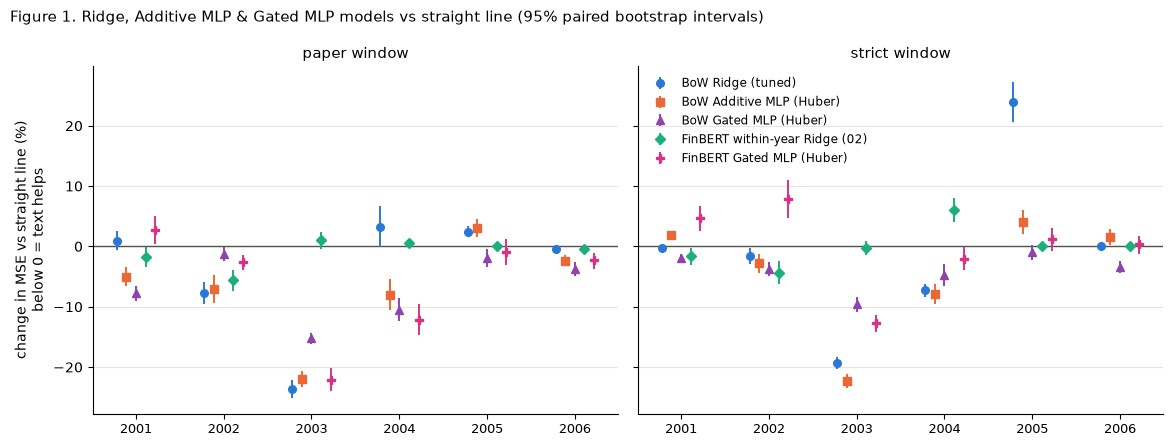

In [12]:
# Figure 1: Year-by-year comparison with 95% paired bootstrap intervals
COLORS = {
    "ridge: words + last year": "#2a78d6",
    ens_name("network: words + last year (Huber, refit)"): "#eb6834",
    ens_name("gated MLP: BoW + last year (Huber, refit)"): "#8e44ad",
    "within-year ridge, Item 7 (FinBERT, from 02)": "#1baf7a",
}
if X_FINBERT_DOC is not None:
    COLORS[ens_name("gated MLP: FinBERT doc + last year (Huber, refit)")] = "#d63384"

MARKERS = dict(zip(COLORS, ["o", "s", "^", "D", "P"]))
OFFSET = dict(zip(COLORS, np.linspace(-0.22, 0.22, len(COLORS))))
LABELS = {
    "ridge: words + last year": "BoW Ridge (tuned)",
    ens_name("network: words + last year (Huber, refit)"): "BoW Additive MLP (Huber)",
    ens_name("gated MLP: BoW + last year (Huber, refit)"): "BoW Gated MLP (Huber)",
    "within-year ridge, Item 7 (FinBERT, from 02)": "FinBERT within-year Ridge (02)",
    ens_name("gated MLP: FinBERT doc + last year (Huber, refit)"): "FinBERT Gated MLP (Huber)",
}

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5), sharey=True)
for ax, window in zip(axes, scoring.WINDOWS):
    ax.axhline(0, color="#52514e", lw=1)
    for name in COLORS:
        r = shown[(shown.model == name) & (shown.window == window)]
        if r.empty:
            continue
        pct, lo, hi = r.change_pct, 100 * r.ci_low / r.baseline_mse, 100 * r.ci_high / r.baseline_mse
        ax.errorbar(r.test_year + OFFSET[name], pct, yerr=[pct - lo, hi - pct],
                    fmt=MARKERS[name], color=COLORS[name], ms=5.5, lw=1.4, capsize=0, label=LABELS[name])
    ax.set_title(f"{window} window", fontsize=11)
    ax.set_xticks(list(scoring.TEST_YEARS))
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("change in MSE vs straight line (%)\nbelow 0 = text helps")
axes[-1].legend(frameon=False, loc="best", fontsize=8.5)
fig.suptitle("Figure 1. Ridge, Additive MLP & Gated MLP models vs straight line (95% paired bootstrap intervals)",
             fontsize=11, x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [13]:
# Level vs. Spread decomposition (main window)
b_ = copy_vs_line[copy_vs_line.window == MAIN_WINDOW].set_index("test_year")
rows = {"line: level as % of its MSE": 100 * b_["baseline_level"] / b_["baseline_mse"]}
decomp_models = [
    "ridge: words + last year",
    ens_name("network: words + last year (Huber, refit)"),
    ens_name("network: within-year words + last year (refit)"),
    ens_name("gated MLP: BoW + last year (Huber, refit)"),
]
if X_FINBERT_DOC is not None:
    decomp_models += [
        ens_name("network: FinBERT + last year (Huber, refit)"),
        ens_name("gated MLP: FinBERT doc + last year (Huber, refit)"),
    ]
if X_CHUNKS is not None:
    decomp_models.append(ens_name("attention-pool FinBERT chunks + gated MLP (Huber, refit)"))

for name in decomp_models:
    r = results[(results.model == name) & (results.window == MAIN_WINDOW)].set_index("test_year")
    rows[f"{name}: level"] = 100 * (r["level"] - r["baseline_level"]) / r["baseline_mse"]
    rows[f"{name}: spread"] = 100 * (r["spread"] - r["baseline_spread"]) / r["baseline_mse"]
pd.DataFrame(rows).T.round(1)

test_year,2001,2002,2003,2004,2005,2006
line: level as % of its MSE,29.9,4.4,44.3,8.4,0.1,1.0
ridge: words + last year: level,0.1,-4.4,-23.6,-6.0,1.9,0.1
ridge: words + last year: spread,0.9,-3.3,-0.0,9.3,0.5,-0.5
"network: words + last year (Huber, refit, 3 seeds averaged): level",-4.7,-4.1,-20.7,-8.4,2.5,-0.2
"network: words + last year (Huber, refit, 3 seeds averaged): spread",-0.3,-3.0,-1.3,0.4,0.5,-2.2
"network: within-year words + last year (refit, 3 seeds averaged): level",1.6,1.4,-14.4,-1.8,-0.0,0.5
"network: within-year words + last year (refit, 3 seeds averaged): spread",0.1,-2.6,1.8,0.6,0.1,-1.2
"gated MLP: BoW + last year (Huber, refit, 3 seeds averaged): level",-6.6,-1.1,-13.5,-7.1,0.0,-0.9
"gated MLP: BoW + last year (Huber, refit, 3 seeds averaged): spread",-1.2,-0.2,-1.7,-3.4,-2.0,-3.0
"network: FinBERT + last year (Huber, refit, 3 seeds averaged): level",12.4,-2.6,-16.4,-7.5,3.0,-0.1


In [14]:
# Takeover sensitivity table (evaluates 3-seed averaged ensembles directly)
def split_preds(window, T):
    train, test = (as_mask(m) for m in scoring.masks(df, T, window))
    p = dict(fit_split(train, test))
    a, b = scoring.fit_line(df, train)
    p["copy last year"], p["straight line"] = prev[test], a + b * prev[test]
    return y[test], p

rows = []
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        yt, p = split_preds(window, T)
        keep = yt >= VERY_LOW
        for name, pt in p.items():
            if ", seed " in name:
                continue
            rows.append({
                "window": window, "test_year": T, "model": name,
                "test_mse": mse(yt, pt),
                "test_mse_excl_takeovers": mse(yt[keep], pt[keep]),
                "takeover_share": 1 - keep.mean(),
            })

tk = (pd.DataFrame(rows).groupby(["window", "model"], sort=False)
      .agg(test_mse=("test_mse", "mean"),
           test_mse_excl_takeovers=("test_mse_excl_takeovers", "mean"),
           reports_dropped=("takeover_share", lambda s: f"{s.mean():.1%}")))
tk.round(3)

test_mse  \
window model                                                          
paper  train mean                                             0.399   
       ridge: words only                                      0.159   
       ridge: words + last year                               0.119   
       network: words only (refit, 3 seeds averaged)          0.153   
       network: words + last year (no refit, 3 seeds a...     0.120   
       network: words + last year (refit, 3 seeds aver...     0.116   
       network: words + last year (Huber, refit, 3 see...     0.116   
       network: within-year words + last year (refit, ...     0.123   
       gated MLP: BoW + last year (Huber, refit, 3 see...     0.117   
       network: FinBERT + last year (refit, 3 seeds av...     0.120   
       network: FinBERT + last year (Huber, refit, 3 s...     0.120   
       gated MLP: FinBERT doc + last year (Huber, refi...     0.118   
       copy last year                                         0.124   
       straight line                                          0.127   
strict train mean                                             0.442   
       ridge: words only                                      0.214   
       ridge: words + last year                               0.129   
       network: words only (refit, 3 seeds averaged)          0.215   
       network: words + last year (no refit, 3 seeds a...     0.139   
       network: words + last year (refit, 3 seeds aver...     0.124   
       network: words + last year (Huber, refit, 3 see...     0.126   
       network: within-year words + last year (refit, ...     0.133   
       gated MLP: BoW + last year (Huber, refit, 3 see...     0.127   
       network: FinBERT + last year (refit, 3 seeds av...     0.129   
       network: FinBERT + last year (Huber, refit, 3 s...     0.128   
       gated MLP: FinBERT doc + last year (Huber, refi...     0.132   
       copy last year                                         0.124   
       straight line                                          0.133   

                                                           test_mse_excl_takeovers  \
window model                                                                         
paper  train mean                                                            0.381   
       ridge: words only                                                     0.144   
       ridge: words + last year                                              0.105   
       network: words only (refit, 3 seeds averaged)                         0.138   
       network: words + last year (no refit, 3 seeds a...                    0.105   
       network: words + last year (refit, 3 seeds aver...                    0.102   
       network: words + last year (Huber, refit, 3 see...                    0.102   
       network: within-year words + last year (refit, ...                    0.108   
       gated MLP: BoW + last year (Huber, refit, 3 see...                    0.103   
       network: FinBERT + last year (refit, 3 seeds av...                    0.105   
       network: FinBERT + last year (Huber, refit, 3 s...                    0.105   
       gated MLP: FinBERT doc + last year (Huber, refi...                    0.103   
       copy last year                                                        0.109   
       straight line                                                         0.112   
strict train mean                                                            0.423   
       ridge: words only                                                     0.197   
       ridge: words + last year                                              0.114   
       network: words only (refit, 3 seeds averaged)                         0.199   
       network: words + last year (no refit, 3 seeds a...                    0.124   
       network: words + last year (refit, 3 seeds aver...                    0.109   
       network: words + last year (H

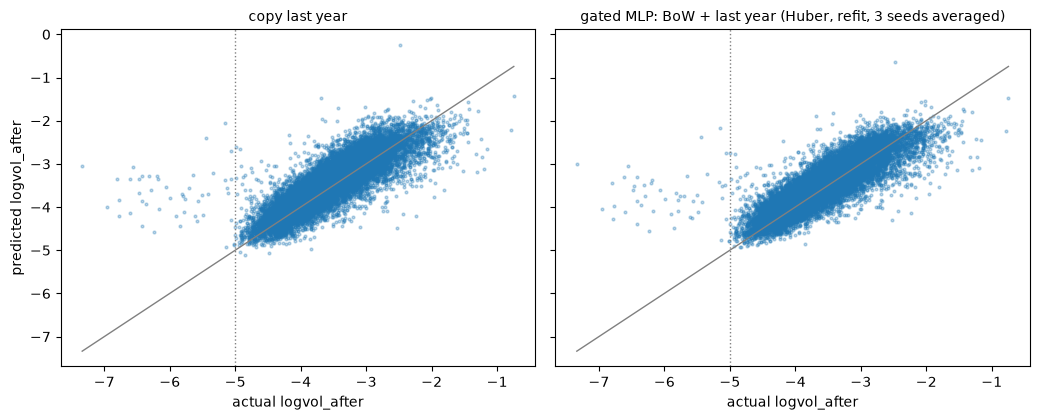

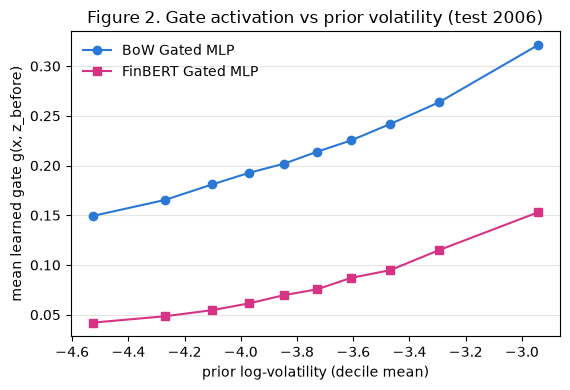

In [15]:
# Interpretability: (1) Predicted vs Actual Scatter, (2) Learned Gate vs Prior Volatility (+ Chunk Attention)
T_LAST = max(scoring.TEST_YEARS)
D_last = DIAGNOSTICS[KEY_OF[(MAIN_WINDOW, T_LAST)]]
te_idx = D_last["te_idx"]
prev_te = prev[te_idx]

parts = [split_preds(MAIN_WINDOW, T) for T in scoring.TEST_YEARS]
yt = np.concatenate([p[0] for p in parts])
best_gated_name = ens_name("gated MLP: BoW + last year (Huber, refit)")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3), sharex=True, sharey=True)
for ax, name in zip(axes, ["copy last year", best_gated_name]):
    ax.scatter(yt, np.concatenate([p[1][name] for p in parts]), s=4, alpha=0.3)
    lims = [yt.min(), yt.max()]
    ax.plot(lims, lims, color="grey", lw=1)
    ax.axvline(VERY_LOW, color="grey", ls=":", lw=1)
    ax.set_xlabel("actual logvol_after")
    ax.set_title(name, fontsize=10)
axes[0].set_ylabel("predicted logvol_after")
plt.tight_layout()
plt.show()

n_plots = 2 if "attn_weights_mean" in D_last else 1
fig, axes = plt.subplots(1, n_plots, figsize=(5.8 * n_plots, 4.0))
if n_plots == 1:
    axes = [axes]

deciles = pd.qcut(prev_te, q=10)
g_df = pd.DataFrame({"prev_logvol": prev_te, "bow_gate": D_last["bow_gate_mean"], "decile": deciles})
g_bow = g_df.groupby("decile", observed=False).agg(prev_mean=("prev_logvol", "mean"), gate_mean=("bow_gate", "mean"))
axes[0].plot(g_bow["prev_mean"], g_bow["gate_mean"], "o-", color="#2a78d6", label="BoW Gated MLP")
if "fb_gate_mean" in D_last:
    g_df["fb_gate"] = D_last["fb_gate_mean"]
    g_fb = g_df.groupby("decile", observed=False).agg(prev_mean=("prev_logvol", "mean"), gate_mean=("fb_gate", "mean"))
    axes[0].plot(g_fb["prev_mean"], g_fb["gate_mean"], "s-", color="#d63384", label="FinBERT Gated MLP")
axes[0].set_xlabel("prior log-volatility (decile mean)")
axes[0].set_ylabel("mean learned gate g(x, z_before)")
axes[0].set_title(f"Figure 2. Gate activation vs prior volatility (test {T_LAST})")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", color="#e6e5e0", lw=0.8)

if "attn_weights_mean" in D_last:
    w_a = D_last["attn_weights_mean"]
    n_valid = CHUNK_MASK[te_idx].sum(axis=1)
    ratio = w_a.max(axis=1) / (1.0 / np.maximum(n_valid, 1))
    axes[1].hist(ratio[n_valid >= 2], bins=30, color="#1baf7a", alpha=0.8)
    axes[1].axvline(1.0, color="#52514e", ls="--", lw=1.2, label="uniform mean-pool (ratio = 1)")
    axes[1].set_xlabel("max attention weight / uniform (1 / M_i)")
    axes[1].set_ylabel("number of reports (M_i >= 2 chunks)")
    axes[1].set_title(f"Chunk attention focus (median ratio = {np.median(ratio[n_valid >= 2]):.2f}x)")
    axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

In [16]:
# 3-Seed Ensemble Word Attribution (Gradient x Input) vs Ridge Coefficients
M = MODELS[KEY_OF[(MAIN_WINDOW, T_LAST)]]
S_last = make_split(*scoring.masks(df, T_LAST, MAIN_WINDOW))
assert (S_last.cols_full == M["cols"]).all(), "features were rebuilt differently from the fit"
words = vocab[M["cols"]]
word_index = {w: j for j, w in enumerate(words)}
print(f"window {MAIN_WINDOW}, test year {T_LAST}: train {KEY_OF[(MAIN_WINDOW, T_LAST)][0][0]}-{KEY_OF[(MAIN_WINDOW, T_LAST)][0][-1]}")

coef = M["ridge_text"].coef_
order_ = np.argsort(coef)
print("ridge, words only -- push volatility DOWN:", words[order_[:15]].tolist())
print("ridge, words only -- push volatility UP:  ", words[order_[::-1][:15]].tolist())

rng = np.random.default_rng(0)
sample = rng.choice(S_last.te_idx, size=min(2000, len(S_last.te_idx)), replace=False)
X_last_t = to_dense_tensor(S_last.X_full)
prev_last_t = torch.from_numpy(S_last.prev_z_full).to(device)
attr = np.zeros(S_last.X_full.shape[1])

for model in M["nets"]:
    model.eval()
    for i in range(0, len(sample), 500):
        r = sample[i:i + 500]
        model.zero_grad(set_to_none=True)
        xb = X_last_t[S_last.pos_full[r]].clone().detach().requires_grad_(True)
        model(xb, prev_last_t[r]).sum().backward()
        attr += (xb.grad * xb).sum(dim=0).detach().cpu().numpy()

attr /= (len(sample) * len(M["nets"]))
order_ = np.argsort(attr)
print("\nnetwork (3-seed refit ensemble), words + last year -- push prediction DOWN:", words[order_[:15]].tolist())
print("network (3-seed refit ensemble), words + last year -- push prediction UP:  ", words[order_[::-1][:15]].tolist())
del X_last_t
gc.collect()

window paper, test year 2006: train 2001-2005
ridge, words only -- push volatility DOWN: ['sharebased', 'dividends', 'esop', 'unsecured', 'policies', 'regulated', 'ferc', 'acquisitions', 'repurchase', 'timing', 'warmer', 'largely', 'distributions', 'coal', 'acquire']
ridge, words only -- push volatility UP:   ['loss', 'nasdaq', 'doubt', 'concern', 'raise', 'financing', 'debenture', 'going', 'smallcap', 'extraordinary', 'reciprocal', 'longlived', 'managements', 'personnel', 'default']

network (3-seed refit ensemble), words + last year -- push prediction DOWN: ['contents', 'stockbased', 'improved', 'billion', 'rate', 'corrections', 'previously', 'eitf', 'contributed', 'repurchase', 'banking', 'earnings', 'timing', 'classified', 'disclosure']
network (3-seed refit ensemble), words + last year -- push prediction UP:   ['sarbanesoxley', 'sharebased', 'loss', 'longlived', 'lease', 'financing', 'vesting', 'administrative', 'fsp', 'impairment', 'sfas', 'prices', 'supersedes', 'similar', 'obli

71

## 5.9 — Computational Cost, Parallelism, Hashing & the 1,000× Scaling Question

Benchmarks four dimensions for a 1,000× production deployment (~27M reports):
1. **Learning curve & data-volume scaling** (`10%, 25%, 50%, 100%` of `S_last.fit_idx`).
2. **Batching bottleneck (sparse-per-batch vs. pre-dense)** and **CPU strong scaling** (`1, 2, 4, 8` threads).
3. **Stateless Map-only `HashingVectorizer` vs. Map-Reduce `CountVectorizer + TF-IDF`** on `T_LAST` texts.
4. **1,000× back-of-envelope extrapolation** for memory, tokenization, and training epochs.

Batching speedup (pre-dense vs sparse-per-batch): 0.202s -> 0.120s (1.69x faster)


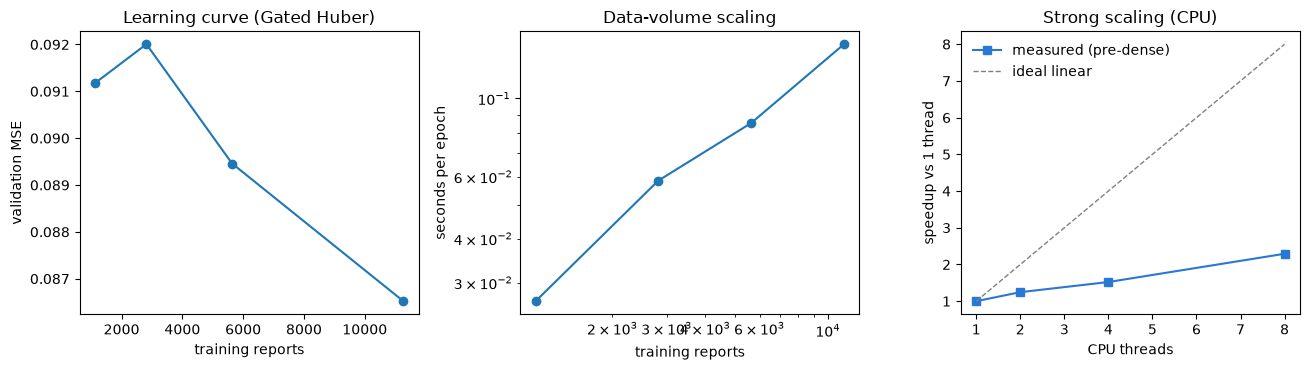

log-log slope of seconds per epoch vs training reports: 0.72 (1.0 = linear)


,fraction,n_train,best_epoch,val_mse,sec_per_epoch,total_seconds
0,0.10,1127,8,0.0912,0.0266,0.6227
1,0.25,2817,4,0.0920,0.0584,0.7181
2,0.50,5635,9,0.0895,0.0851,1.4367
3,1.00,11271,26,0.0865,0.1426,5.0547


,threads,sec_per_epoch,speedup
0,1,0.275,1.000
1,2,0.221,1.246
2,4,0.181,1.522
3,8,0.120,2.292


,method,n_reports,seconds,reports_per_sec,csr_MB,needs_global_vocab
0,CountVectorizer + TF-IDF (Map-Reduce),3003,23.353,128.590,26.387,True
1,HashingVectorizer (Stateless Map-Only),3003,21.296,141.014,25.923,False



--- 1,000x Back-of-Envelope Extrapolation ---
reports: 27,142  ->  27,142,000
sparse feature table (one split): 141 MB  ->  141 GB (8.1 kB per report)
counting words (one pass, one core): 1.5 min  ->  25 hours
one training epoch (pre-dense CPU): 0.143 s  ->  0.04 hours (linear)
network parameters: 80,054 (fixed by N_WORDS=5000 and HIDDEN=16, independent of N)


8379

In [17]:
X_last_tune_t = to_dense_tensor(S_last.X_tune)
y_last_fit_t = torch.from_numpy(S_last.y_z_fit).to(device)
prev_last_fit_t = torch.from_numpy(S_last.prev_z_fit).to(device)

# 1. Learning curve & data-volume scaling (using GatedInteractionMLP with Huber loss)
rng = np.random.default_rng(0)
lc_rows = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    sub = S_last.fit_idx if frac == 1.0 else rng.choice(S_last.fit_idx, size=int(frac * len(S_last.fit_idx)), replace=False)
    t0 = time.perf_counter()
    _, hist, bep = train_nn_fast(
        X_last_tune_t, S_last.pos_tune, y_last_fit_t, prev_last_fit_t, sub, S_last.val_idx, S_last.sd_fit,
        use_prev=True, gated=True, seed=0, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
        loss_type="huber", huber_delta=HUBER_DELTA, use_val=True,
    )
    lc_rows.append({
        "fraction": frac, "n_train": len(sub), "best_epoch": bep,
        "val_mse": hist["val_mse"].min(), "sec_per_epoch": hist["seconds"].mean(),
        "total_seconds": time.perf_counter() - t0,
    })
lc = pd.DataFrame(lc_rows)

# 2. Sparse-per-batch vs Pre-dense & CPU Strong Scaling
def bench_sparse_epoch(S_obj, n_epochs=3):
    torch.manual_seed(0)
    rng_ = np.random.default_rng(0)
    m = GatedInteractionMLP(S_obj.X_tune.shape[1], hidden=HIDDEN, dropout=DROPOUT).to(device)
    opt = make_optimizer(m)
    loss_fn = make_loss("huber", HUBER_DELTA)
    secs = []
    for _ in range(n_epochs):
        t0 = time.perf_counter()
        order_ = rng_.permutation(S_obj.fit_idx)
        for i in range(0, len(order_), BATCH):
            r = order_[i:i + BATCH]
            opt.zero_grad(set_to_none=True)
            xb = torch.from_numpy(S_obj.X_tune[S_obj.pos_tune[r]].toarray()).to(device)
            loss = loss_fn(m(xb, prev_last_fit_t[r]), y_last_fit_t[r])
            loss.backward()
            opt.step()
        secs.append(time.perf_counter() - t0)
    return float(np.mean(secs))

sparse_sec = bench_sparse_epoch(S_last, n_epochs=3)

orig_threads = torch.get_num_threads()
max_cores = os.cpu_count() or 4
thread_counts = sorted({t for t in [1, 2, 4, 8] if t <= max_cores})
thread_rows = []
for n_th in thread_counts:
    torch.set_num_threads(n_th)
    _, hist_th, _ = train_nn_fast(
        X_last_tune_t, S_last.pos_tune, y_last_fit_t, prev_last_fit_t,
        S_last.fit_idx, S_last.val_idx, S_last.sd_fit,
        use_prev=True, gated=True, seed=0, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
        loss_type="huber", huber_delta=HUBER_DELTA, max_epochs=5, use_val=False,
    )
    thread_rows.append({"threads": n_th, "sec_per_epoch": hist_th["seconds"].mean()})
torch.set_num_threads(orig_threads)

th_df = pd.DataFrame(thread_rows)
th_df["speedup"] = th_df["sec_per_epoch"].iloc[0] / th_df["sec_per_epoch"]
print(f"Batching speedup (pre-dense vs sparse-per-batch): {sparse_sec:.3f}s -> {th_df['sec_per_epoch'].min():.3f}s "
      f"({sparse_sec / th_df['sec_per_epoch'].min():.2f}x faster)")

# 3. Stateless HashingVectorizer vs Map-Reduce CountVectorizer + TF-IDF
texts_last = load_year_texts(T_LAST)

t0 = time.perf_counter()
cv = CountVectorizer(min_df=MIN_DF, stop_words="english", token_pattern=TOKEN, max_features=N_WORDS, dtype=np.int32)
X_cv = TfidfTransformer(sublinear_tf=True).fit_transform(cv.fit_transform(texts_last)).astype(np.float32)
t_cv = time.perf_counter() - t0
bytes_cv = X_cv.data.nbytes + X_cv.indices.nbytes + X_cv.indptr.nbytes

t0 = time.perf_counter()
hv = HashingVectorizer(n_features=N_WORDS, stop_words="english", token_pattern=TOKEN,
                       alternate_sign=False, norm="l2", dtype=np.float32)
X_hv = hv.transform(texts_last)
t_hv = time.perf_counter() - t0
bytes_hv = X_hv.data.nbytes + X_hv.indices.nbytes + X_hv.indptr.nbytes

vec_bench = pd.DataFrame([
    {"method": "CountVectorizer + TF-IDF (Map-Reduce)", "n_reports": len(texts_last),
     "seconds": t_cv, "reports_per_sec": len(texts_last) / t_cv,
     "csr_MB": bytes_cv / 1e6, "needs_global_vocab": True},
    {"method": "HashingVectorizer (Stateless Map-Only)", "n_reports": len(texts_last),
     "seconds": t_hv, "reports_per_sec": len(texts_last) / t_hv,
     "csr_MB": bytes_hv / 1e6, "needs_global_vocab": False},
])

# 3-panel scaling figure
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.8))
axes[0].plot(lc["n_train"], lc["val_mse"], "o-")
axes[0].set_xlabel("training reports"); axes[0].set_ylabel("validation MSE"); axes[0].set_title("Learning curve (Gated Huber)")

axes[1].loglog(lc["n_train"], lc["sec_per_epoch"], "o-")
axes[1].set_xlabel("training reports"); axes[1].set_ylabel("seconds per epoch"); axes[1].set_title("Data-volume scaling")

axes[2].plot(th_df["threads"], th_df["speedup"], "s-", color="#2a78d6", label="measured (pre-dense)")
axes[2].plot(th_df["threads"], th_df["threads"], "--", color="grey", lw=1, label="ideal linear")
axes[2].set_xlabel("CPU threads"); axes[2].set_ylabel("speedup vs 1 thread"); axes[2].set_title("Strong scaling (CPU)")
axes[2].legend(frameon=False)
plt.tight_layout()
plt.show()

slope_time = np.polyfit(np.log(lc["n_train"]), np.log(lc["sec_per_epoch"]), 1)[0]
print(f"log-log slope of seconds per epoch vs training reports: {slope_time:.2f} (1.0 = linear)")
display(lc.round(4))
display(th_df.round(3))
display(vec_bench.round(3))

# 4. 1,000x back-of-envelope extrapolation
FACTOR = 1000
full = lc.iloc[-1]
csr_bytes = S_last.X_full.data.nbytes + S_last.X_full.indices.nbytes + S_last.X_full.indptr.nbytes
n_params = sum(p.numel() for p in GatedInteractionMLP(N_WORDS, HIDDEN, DROPOUT).parameters())
count_secs = timings["count_seconds"]

print("\n--- 1,000x Back-of-Envelope Extrapolation ---")
print(f"reports: {len(df):,}  ->  {len(df) * FACTOR:,.0f}")
print(f"sparse feature table (one split): {csr_bytes / 1e6:,.0f} MB  ->  {csr_bytes * FACTOR / 1e9:,.0f} GB "
      f"({csr_bytes / S_last.X_full.shape[0] / 1e3:.1f} kB per report)")
print(f"counting words (one pass, one core): {count_secs / 60:,.1f} min  ->  {count_secs * FACTOR / 3600:,.0f} hours")
print(f"one training epoch (pre-dense CPU): {full['sec_per_epoch']:.3f} s  ->  {full['sec_per_epoch'] * FACTOR / 3600:,.2f} hours (linear)")
print(f"network parameters: {n_params:,} (fixed by N_WORDS={N_WORDS} and HIDDEN={HIDDEN}, independent of N)")

del X_last_tune_t
gc.collect()

## 5.10 — Conclusions & Interpretations *(Write in Your Own Words After Final Run)*

- **Progression from baseline to gated MLP:** Contrast `no refit` vs. `refit`, `MSE` vs. `Huber`, and `ResidualTextNet` vs. `GatedInteractionMLP` across `paper` and `strict` windows.
- **2 × 2 representation insight (`level` vs. `spread`):** Highlight why `gated MLP: BoW` leads on total MSE while `gated MLP: FinBERT doc` leads on cross-sectional company `spread`, and why target-only demeaning in `within-year MLP` did not eliminate out-of-sample level shifts.
- **Economic meaning of the learned gate:** Discuss why both BoW and FinBERT gated models open the text gate ~3× wider for high-volatility firms than calm firms.
- **1,000× scaling & further development:** Summarize the learning curve, CPU strong-scaling wall, Map-Reduce `CountVectorizer` vs. Map-only `HashingVectorizer`, and GPU execution of `FinBERTAttentionNet` on 512-token chunks.